
# Retuning XGBoost by MAE on the new descriptors

*Author: Suhmi. Builds on notebooks 04 (tuning), 05 (multi-task network) and 06 (chain descriptors).*

## Purpose

The XGBoost settings used so far were chosen in notebook 04 (section 24):

- by **R²**, before the coach asked for MAE as the metric,
- on the old feature sets (B+ or B+ + D), before the chain and shape descriptors existed.

This notebook repeats the search with **MAE** as the criterion on the new feature sets,
then rebuilds the ensemble with the multi-task network (notebook 06, section 7).

## Rules

- The same 80/20 split per target and the same five folds as notebooks 04–06.
- **The validation subsets are frozen** and are not used anywhere in this notebook.
  They are scored only once more, at the very end of the project.
- The same search ranges as notebook 04. With the same random state, the first
  30 candidate settings are exactly those of notebook 04; 10 more are added (40 in total).


## 1. Setup

In [1]:

import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import loguniform, randint, uniform
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, train_test_split
from sklearn.pipeline import make_pipeline
from xgboost import XGBRegressor

# Make the project's src package importable from the notebooks folder
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.multitask_network import fit_network
from src.polymer_features import SHAPE_COLUMNS, build_chain_features, build_features

RANDOM_STATE = 42
VALIDATION_FRACTION = 0.20
N_FOLDS = 5
N_SEARCH_ITERATIONS = 40

torch.set_num_threads(8)

target_columns = ["Tg", "FFV", "Tc", "Density", "Rg"]
units = {"Tg": "°C", "FFV": "–", "Tc": "W/(m·K)", "Density": "g/cm³", "Rg": "Å"}


## 2. Features, splits and folds

In [2]:

train = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "train.csv")

bplus_df, fingerprint_df = build_features(train["SMILES"])
chain_df = build_chain_features(train["SMILES"])
shape_df = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "shape_descriptors.csv",
                       index_col=0)[SHAPE_COLUMNS]
assert shape_df.index.equals(train.index)

feature_sets = {
    "B+": bplus_df,
    "B+ + D": pd.concat([bplus_df, fingerprint_df], axis=1),
    "B+ + chain + shape": pd.concat([bplus_df, chain_df, shape_df], axis=1),
    "B+ + chain + shape + D": pd.concat([bplus_df, chain_df, shape_df, fingerprint_df], axis=1),
}
for name, features in feature_sets.items():
    print(f"{name}: {features.shape[1]} features")

cv_folds = KFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
labels = train[target_columns].to_numpy(dtype=float)

# Only the training subsets are kept; the validation subsets are never touched here
train_rows, fold_rows = {}, {}
for target in target_columns:
    labelled = train.index[train[target].notna()]
    train_index, _ = train_test_split(
        labelled, test_size=VALIDATION_FRACTION, random_state=RANDOM_STATE, shuffle=True
    )
    train_rows[target] = np.asarray(train_index)
    fold_rows[target] = [train_rows[target][test_idx] for _, test_idx in cv_folds.split(train_index)]

expected_sizes = {"Tg": 408, "FFV": 5624, "Tc": 589, "Density": 490, "Rg": 491}
assert {t: len(rows) for t, rows in train_rows.items()} == expected_sizes

# Median baseline MAE per target and fold, for the error reduction
baseline_mae = {
    (target, fold): np.mean(np.abs(
        labels[fold_rows[target][fold], t]
        - np.median(labels[np.setdiff1d(train_rows[target], fold_rows[target][fold]), t])
    ))
    for t, target in enumerate(target_columns) for fold in range(N_FOLDS)
}


B+: 43 features
B+ + D: 1067 features
B+ + chain + shape: 73 features
B+ + chain + shape + D: 1097 features



## 3. Tuning by MAE

For each target, XGBoost is tuned on the two new feature sets: all 73 descriptors
without and with the fingerprints. Each search tries 40 settings with 5-fold
cross-validation and selects the setting with the lowest mean MAE.
This step takes roughly 30–45 minutes.


In [3]:

# Same search ranges as notebook 04, section 20.12
xgb_search_space = {
    "n_estimators": randint(200, 1501),
    "learning_rate": loguniform(0.01, 0.2),
    "max_depth": randint(2, 9),
    "min_child_weight": randint(1, 11),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_lambda": loguniform(0.1, 10),
}
tuning_sets = ["B+ + chain + shape", "B+ + chain + shape + D"]

tuning_rows = []
start = time.time()

for t, target in enumerate(target_columns):
    rows = train_rows[target]
    # Folds as positions within the training subset, identical to fold_rows
    fold_positions = [(np.flatnonzero(~np.isin(rows, test)), np.flatnonzero(np.isin(rows, test)))
                      for test in fold_rows[target]]

    for set_name in tuning_sets:
        X_train = feature_sets[set_name].to_numpy(dtype=float)[rows]
        pipeline = make_pipeline(SimpleImputer(strategy="median"),
                                 XGBRegressor(random_state=RANDOM_STATE, n_jobs=1))
        search = RandomizedSearchCV(
            pipeline,
            param_distributions={f"xgbregressor__{k}": v for k, v in xgb_search_space.items()},
            n_iter=N_SEARCH_ITERATIONS,
            scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
            refit=False,
            cv=fold_positions,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
        search.fit(X_train, labels[rows, t])

        results = search.cv_results_
        best = int(np.argmax(results["mean_test_mae"]))
        fold_reduction = [100 * (1 + results[f"split{k}_test_mae"][best] / baseline_mae[(target, k)])
                          for k in range(N_FOLDS)]
        tuning_rows.append({
            "target": target, "feature_set": set_name,
            "MAE": -results["mean_test_mae"][best],
            "error_reduction": np.mean(fold_reduction),
            "error_reduction_std": np.std(fold_reduction),
            "R2": results["mean_test_r2"][best],
            "best_candidate": best,
            "params": {k.split("__")[1]: v for k, v in results["params"][best].items()},
        })
        print(f"{target}, {set_name} done ({time.time() - start:.0f} s)")

tuning_df = pd.DataFrame(tuning_rows)
display(tuning_df.drop(columns="params").round(4))


Tg, B+ + chain + shape done (37 s)


Tg, B+ + chain + shape + D done (65 s)


FFV, B+ + chain + shape done (109 s)


FFV, B+ + chain + shape + D done (229 s)


Tc, B+ + chain + shape done (243 s)


Tc, B+ + chain + shape + D done (269 s)


Density, B+ + chain + shape done (279 s)


Density, B+ + chain + shape + D done (300 s)


Rg, B+ + chain + shape done (314 s)


Rg, B+ + chain + shape + D done (339 s)


,target,feature_set,MAE,error_reduction,error_reduction_std,R2,best_candidate
0,Tg,B+ + chain + shape,48.8102,44.9180,2.1620,0.6820,28
1,Tg,B+ + chain + shape + D,48.3087,45.4602,2.1966,0.6875,28
2,FFV,B+ + chain + shape,0.0069,66.4151,2.0323,0.7639,33
3,FFV,B+ + chain + shape + D,0.0058,71.8821,1.5272,0.8147,33
4,Tc,B+ + chain + shape,0.0262,65.2379,3.1427,0.8180,6
5,Tc,B+ + chain + shape + D,0.0252,66.5577,2.4735,0.8251,6
6,Density,B+ + chain + shape,0.0231,78.1336,2.6782,0.9310,3
7,Density,B+ + chain + shape + D,0.0226,78.5248,2.2145,0.9306,16
8,Rg,B+ + chain + shape,1.2780,67.2929,2.1798,0.8267,16
9,Rg,B+ + chain + shape + D,1.2833,67.1457,2.5276,0.8214,15


In [4]:

# Best feature set per target, and its selected settings
mae_tuned = tuning_df.loc[tuning_df.groupby("target")["MAE"].idxmin()].set_index("target").loc[target_columns]

for target, row in mae_tuned.iterrows():
    params = ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}"
                       for k, v in row["params"].items())
    origin = "notebook 04 candidate" if row["best_candidate"] < 30 else "new candidate"
    print(f"{target} ({row['feature_set']}, {origin}): {params}")


Tg (B+ + chain + shape + D, notebook 04 candidate): colsample_bytree=0.739, learning_rate=0.0133, max_depth=2, min_child_weight=1, n_estimators=750, reg_lambda=7.47, subsample=0.655
FFV (B+ + chain + shape + D, new candidate): colsample_bytree=0.641, learning_rate=0.073, max_depth=6, min_child_weight=2, n_estimators=1077, reg_lambda=1.25, subsample=0.877
Tc (B+ + chain + shape + D, notebook 04 candidate): colsample_bytree=0.722, learning_rate=0.0134, max_depth=5, min_child_weight=7, n_estimators=708, reg_lambda=4.64, subsample=0.669
Density (B+ + chain + shape + D, notebook 04 candidate): colsample_bytree=0.61, learning_rate=0.0138, max_depth=8, min_child_weight=7, n_estimators=1464, reg_lambda=0.425, subsample=0.803
Rg (B+ + chain + shape, notebook 04 candidate): colsample_bytree=0.61, learning_rate=0.0138, max_depth=8, min_child_weight=7, n_estimators=1464, reg_lambda=0.425, subsample=0.803



## 4. Ensemble with the MAE-tuned XGBoost

The candidates are compared on the same five folds:

- **Network:** the multi-task network on the 73 descriptors (as in notebook 06, section 7).
- **XGBoost (R²-tuned):** the settings from notebook 04 with the feature set chosen
  in notebook 06 (the current final tree model).
- **XGBoost (MAE-tuned):** the settings and feature set selected in section 3.
- **Ensembles:** the network averaged 50/50 with each XGBoost model.

The final model per target is the candidate with the lowest cross-validated MAE.
Because the MAE-tuned settings were selected on these same folds, their scores are
slightly optimistic.


In [5]:

# Settings from notebook 04, section 24 (selected by R²)
r2_params = {
    "Tg": dict(n_estimators=750, learning_rate=0.013339162948869679, max_depth=2,
               min_child_weight=1, subsample=0.6550083776583973,
               colsample_bytree=0.7394663949166917, reg_lambda=7.472397689332939),
    "FFV": dict(n_estimators=1464, learning_rate=0.013815607382950859, max_depth=8,
                min_child_weight=7, subsample=0.8034282764658811,
                colsample_bytree=0.610167650697638, reg_lambda=0.4253162363790871),
    "Tc": dict(n_estimators=708, learning_rate=0.013399060561509796, max_depth=5,
               min_child_weight=7, subsample=0.6693458614031088,
               colsample_bytree=0.7218455076693483, reg_lambda=4.638630972397279),
    "Density": dict(n_estimators=1464, learning_rate=0.013815607382950859, max_depth=8,
                    min_child_weight=7, subsample=0.8034282764658811,
                    colsample_bytree=0.610167650697638, reg_lambda=0.4253162363790871),
    "Rg": dict(n_estimators=1031, learning_rate=0.018187859051288217, max_depth=8,
               min_child_weight=4, subsample=0.9439761626945282,
               colsample_bytree=0.9140703845572055, reg_lambda=0.85807606199213),
}
# Feature sets of the current final tree models (notebook 06, section 7)
r2_sets = {"Tg": "B+ + chain + shape + D", "FFV": "B+ + chain + shape + D", "Tc": "B+ + D",
           "Density": "B+ + chain + shape + D", "Rg": "B+ + chain"}
feature_sets["B+ + chain"] = pd.concat([bplus_df, chain_df], axis=1)

xgboost_choices = {
    "XGBoost (R²-tuned)": {t: (r2_sets[t], r2_params[t]) for t in target_columns},
    "XGBoost (MAE-tuned)": {t: (mae_tuned.loc[t, "feature_set"], mae_tuned.loc[t, "params"])
                            for t in target_columns},
}
X_network = feature_sets["B+ + chain + shape"].to_numpy(dtype=float)

ensemble_rows = []
start = time.time()

for fold in range(N_FOLDS):
    Y_fold = np.full_like(labels, np.nan)
    for t, target in enumerate(target_columns):
        fit_rows = np.setdiff1d(train_rows[target], fold_rows[target][fold])
        Y_fold[fit_rows, t] = labels[fit_rows, t]

    # Same seed as notebooks 05 and 06
    has_label = ~np.isnan(Y_fold).all(axis=1)
    predict_network = fit_network(X_network[has_label], Y_fold[has_label], seed=RANDOM_STATE + fold)

    for t, target in enumerate(target_columns):
        rows = fold_rows[target][fold]
        fit_rows = np.flatnonzero(~np.isnan(Y_fold[:, t]))
        y_true = labels[rows, t]

        predictions = {"Network": predict_network(X_network[rows])[:, t]}
        for model_name, choice in xgboost_choices.items():
            set_name, params = choice[target]
            X_set = feature_sets[set_name].to_numpy(dtype=float)
            xgboost = make_pipeline(SimpleImputer(strategy="median"),
                                    XGBRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1))
            predictions[model_name] = xgboost.fit(X_set[fit_rows], Y_fold[fit_rows, t]).predict(X_set[rows])
            predictions[f"Ensemble, {model_name}"] = (predictions["Network"] + predictions[model_name]) / 2

        for model_name, y_pred in predictions.items():
            mae = mean_absolute_error(y_true, y_pred)
            ensemble_rows.append({"target": target, "model": model_name, "fold": fold, "MAE": mae,
                                  "error_reduction": 100 * (1 - mae / baseline_mae[(target, fold)]),
                                  "R2": r2_score(y_true, y_pred)})

    print(f"Fold {fold + 1} done ({time.time() - start:.0f} s)")

ensemble_df = pd.DataFrame(ensemble_rows)


Fold 1 done (30 s)


Fold 2 done (51 s)


Fold 3 done (72 s)


Fold 4 done (94 s)


Fold 5 done (115 s)


Cross-validated error_reduction (mean over 5 folds)


model,Network,XGBoost (R²-tuned),XGBoost (MAE-tuned),"Ensemble, XGBoost (R²-tuned)","Ensemble, XGBoost (MAE-tuned)"
target,,,,,
Tg,41.2,45.6,45.6,45.9,45.9
FFV,61.7,70.4,72.0,68.3,69.5
Tc,64.5,66.6,66.5,67.1,67.0
Density,74.0,78.6,78.6,78.3,78.3
Rg,65.3,66.7,67.0,68.5,68.0


Cross-validated MAE (mean over 5 folds)


model,Network,XGBoost (R²-tuned),XGBoost (MAE-tuned),"Ensemble, XGBoost (R²-tuned)","Ensemble, XGBoost (MAE-tuned)"
target,,,,,
Tg,52.1187,48.1637,48.1637,47.9336,47.9336
FFV,0.0079,0.0061,0.0058,0.0065,0.0063
Tc,0.0268,0.0252,0.0252,0.0247,0.0248
Density,0.0268,0.0226,0.0226,0.0227,0.0227
Rg,1.3564,1.3004,1.2906,1.2333,1.2493


Cross-validated R2 (mean over 5 folds)


model,Network,XGBoost (R²-tuned),XGBoost (MAE-tuned),"Ensemble, XGBoost (R²-tuned)","Ensemble, XGBoost (MAE-tuned)"
target,,,,,
Tg,0.630,0.687,0.687,0.689,0.689
FFV,0.744,0.807,0.820,0.795,0.803
Tc,0.830,0.829,0.825,0.845,0.842
Density,0.903,0.931,0.931,0.928,0.928
Rg,0.823,0.824,0.822,0.844,0.840


,current final model,current error reduction,new final model,new error reduction,fold std (new),unit,new MAE,gain (points)
Tg,"Ensemble, XGBoost (R²-tuned)",45.9027,"Ensemble, XGBoost (R²-tuned)",45.9027,2.2747,°C,47.9336,0.000
FFV,XGBoost (R²-tuned),70.4052,XGBoost (MAE-tuned),72.0482,1.6355,–,0.0058,1.643
Tc,"Ensemble, XGBoost (R²-tuned)",67.1218,"Ensemble, XGBoost (R²-tuned)",67.1218,3.6841,W/(m·K),0.0247,0.000
Density,XGBoost (R²-tuned),78.5871,XGBoost (R²-tuned),78.5871,2.5515,g/cm³,0.0226,0.000
Rg,"Ensemble, XGBoost (R²-tuned)",68.4537,"Ensemble, XGBoost (R²-tuned)",68.4537,2.0024,Å,1.2333,0.000


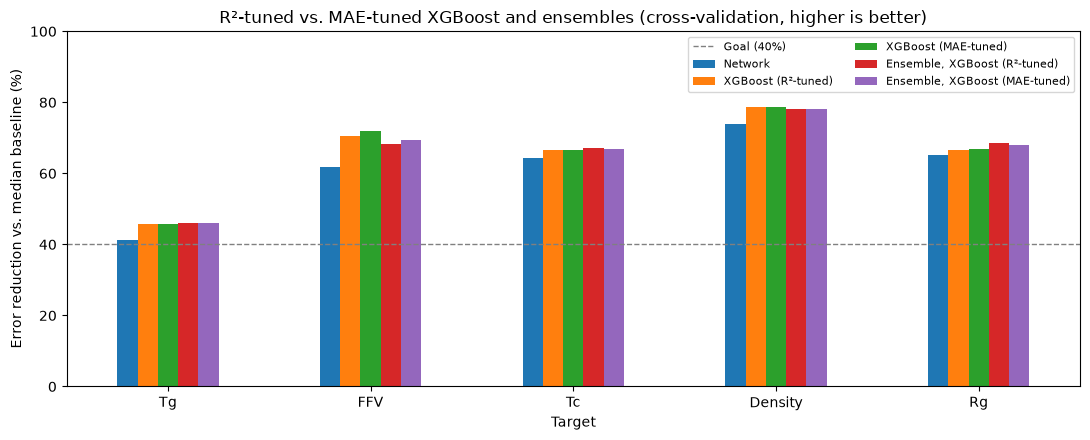

In [6]:

model_order = ["Network", "XGBoost (R²-tuned)", "XGBoost (MAE-tuned)",
               "Ensemble, XGBoost (R²-tuned)", "Ensemble, XGBoost (MAE-tuned)"]

for value in ["error_reduction", "MAE", "R2"]:
    print(f"Cross-validated {value} (mean over 5 folds)")
    display(ensemble_df.pivot_table(index="target", columns="model", values=value)
            .loc[target_columns, model_order].round(4 if value == "MAE" else 3 if value == "R2" else 1))

# Current final models (notebook 06) and the new choice by lowest cross-validated MAE
current_final = {"Tg": "Ensemble, XGBoost (R²-tuned)", "FFV": "XGBoost (R²-tuned)",
                 "Tc": "Ensemble, XGBoost (R²-tuned)", "Density": "XGBoost (R²-tuned)",
                 "Rg": "Ensemble, XGBoost (R²-tuned)"}
cv_mae = ensemble_df.groupby(["target", "model"])["MAE"].mean().unstack()
new_final = cv_mae.loc[target_columns, model_order].idxmin(axis=1).to_dict()

reduction = ensemble_df.groupby(["target", "model"])["error_reduction"].agg(["mean", "std"])
comparison = pd.DataFrame({
    "current final model": current_final,
    "current error reduction": {t: reduction.loc[(t, m), "mean"] for t, m in current_final.items()},
    "new final model": new_final,
    "new error reduction": {t: reduction.loc[(t, m), "mean"] for t, m in new_final.items()},
    "fold std (new)": {t: reduction.loc[(t, m), "std"] for t, m in new_final.items()},
    "unit": units,
    "new MAE": {t: cv_mae.loc[t, m] for t, m in new_final.items()},
}).loc[target_columns]
comparison["gain (points)"] = comparison["new error reduction"] - comparison["current error reduction"]
display(comparison.round(4))

ax = (ensemble_df.pivot_table(index="target", columns="model", values="error_reduction")
      .loc[target_columns, model_order].plot(kind="bar", figsize=(11, 4.5), rot=0))
ax.axhline(40, color="grey", linestyle="--", linewidth=1, label="Goal (40%)")
ax.set_ylim(0, 100)
ax.set_ylabel("Error reduction vs. median baseline (%)")
ax.set_xlabel("Target")
ax.set_title("R²-tuned vs. MAE-tuned XGBoost and ensembles (cross-validation, higher is better)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()


#### Findings: tuning by MAE

**Settings selected by MAE** (40 candidates, 5 folds; the first 30 are the candidates of notebook 04):

| Target | Best feature set | Selected setting | Same as the R²-tuned setting? |
|---|---|---|:---:|
| Tg | 73 descriptors + D | notebook 04 candidate | yes |
| FFV | 73 descriptors + D | **new candidate** (depth 6, learning rate 0.07, 1,077 trees) | no |
| Tc | 73 descriptors + D | notebook 04 candidate | yes |
| Density | 73 descriptors + D | notebook 04 candidate | yes |
| Rg | 73 descriptors | another notebook 04 candidate (the FFV/Density setting) | no |

**Cross-validated error reduction of the final models (%):**

| Target | Current final model | MAE-tuned choice | Gain (points) | Fold std | MAE |
|---|---|---|---:|---:|---|
| Tg | ensemble: 45.9 | unchanged | 0 | 2.3 | 47.9 °C |
| FFV | XGBoost: 70.4 | **MAE-tuned XGBoost: 72.0** | **+1.6** | 1.6 | 0.0061 → 0.0058 |
| Tc | ensemble: 67.1 | unchanged | 0 | 3.7 | 0.0247 W/(m·K) |
| Density | XGBoost: 78.6 | unchanged | 0 | 2.6 | 0.0226 g/cm³ |
| Rg | ensemble: 68.5 | unchanged | 0 | 2.0 | 1.23 Å |

- **Choosing the settings by MAE instead of R² changes almost nothing.** For Tg, Tc and
  Density, MAE selects exactly the same setting as R². The limitation noted in notebooks 04–06
  ("tuned by R², not by MAE") therefore had no real effect.
- **FFV** is the only target that improves: a new, faster-learning setting lowers the MAE from
  0.0061 to 0.0058 (+1.6 points, about one fold standard deviation). FFV has by far the most
  data (5,624 training polymers), so it can use a less conservative model.
- For Rg, the MAE-tuned XGBoost alone is slightly better (+0.3 points), but in the ensemble
  the R²-tuned one stays better (68.5 vs. 68.0), so the final model does not change.
- The fingerprints help or are neutral for every target except Rg (−0.1 points, i.e. no difference).
- The gains are selected on the same folds, so they are slightly optimistic.

**Decision:** the final models stay as in notebook 06, except **FFV**, which now uses the
MAE-tuned XGBoost on all 73 descriptors + fingerprints. The validation subsets were not used;
they will be scored once at the end of the project.
